# Supply / demand forecasting pipeline
The pipeline **refuses to forecast** with fewer than 56 days of real data. The demo below uses a **SYNTHETIC** series purely to show the pipeline; its metrics say nothing about real donations. Replace `df` with a DB export (`date, supply_qty, demand_qty, category`).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

In [2]:
import pandas as pd, json
from app.services import forecasting_service as F
print(F.run_forecast([], 7)['message'])  # what happens without data

At least 56 days of real, daily donation-supply and recipient-demand records are required (more is better). Export them from the platform database (date, supply_qty, demand_qty, optional category) and call the endpoint again. No forecast has been fabricated.


In [3]:
df = F.generate_synthetic_series(140)   # SYNTHETIC demo data
res = F.run_forecast(df.to_dict('records'), 7)
ev = res['targets']['demand']['evaluation']
print(ev['splits'], 'selected:', ev['selected_model'])
pd.DataFrame({m: v['test'] for m, v in ev['results'].items() if 'test' in v}).T.round(2)

{'train_days': 98, 'validation_days': 21, 'test_days': 21} selected: linear_regression


,MAE,RMSE,sMAPE_pct,MASE
naive_last,18.55,23.06,11.15,1.00
moving_average_7,15.91,19.97,9.49,0.86
seasonal_naive_7,20.70,25.10,12.15,1.11
linear_regression,14.87,18.92,8.87,0.80
random_forest,15.82,20.62,9.41,0.85
holt_winters,15.21,19.06,9.08,0.82


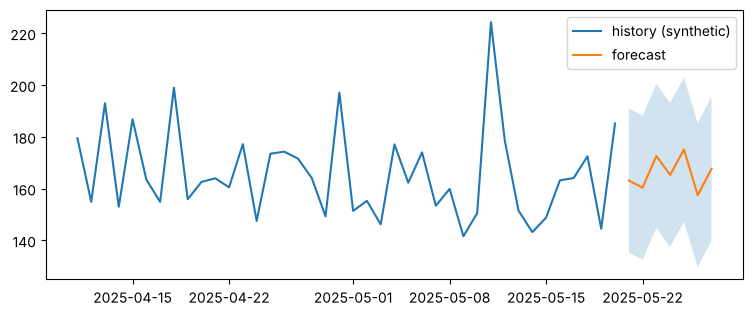

In [4]:
import matplotlib.pyplot as plt
y = F.to_daily(df, 'demand_qty'); fc = pd.DataFrame(res['targets']['demand']['forecast'])
plt.figure(figsize=(9,3.5)); plt.plot(y.index[-40:], y.values[-40:], label='history (synthetic)')
plt.plot(pd.to_datetime(fc.date), fc.forecast, label='forecast'); plt.fill_between(pd.to_datetime(fc.date), fc.lower_90, fc.upper_90, alpha=.2)
plt.legend(); plt.show()